# Emendas parlamentares e reeleição dos deputados federais (2023–2026)

Duas perguntas:
1. **Descritiva:** quanto os deputados federais destinaram em emendas na 57ª legislatura, de que tipo, quando foi pago
   e para onde foi.
2. **Pergunta A:** entre os 513 deputados eleitos em 2022, quem destinou mais emendas, ou as concentrou na própria base
   eleitoral, se reelegeu mais em 2026?

Os dados vêm de `uv run coletar-legislativo` (Portal da Transparência, TSE e Câmara). A tabela por deputado é montada por
`eleicoes_2026.emendas.painel_deputados()`.

**O que este notebook não consegue dizer.** É uma análise de associação, não de causa: deputados que já eram fortes podem
tanto conseguir executar mais emendas quanto se reeleger mais. As receitas de campanha de 2026, principal fator conhecido
de reeleição, entram como controle, mas ainda são as declaradas até agora: a prestação de contas final vence 30 dias depois
da eleição.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

from eleicoes_2026 import emendas as E

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (11, 5), "figure.dpi": 110, "axes.titleweight": "bold"})
pd.options.display.float_format = "{:,.2f}".format

emendas = pd.read_parquet(E.LEG / "emendas.parquet")
pagos = pd.read_parquet(E.LEG / "emendas_pagamentos.parquet")
dep = E.painel_deputados()
print(f"{len(emendas):,} linhas de emendas, {len(pagos):,} pagamentos, {len(dep)} deputados eleitos em 2022")

94,747 linhas de emendas, 828,478 pagamentos, 513 deputados eleitos em 2022


## 1. Quanto e de que tipo
Valores em R$ bilhões, por ano do orçamento. **Empenhado** é o valor reservado; **pago** é o que saiu no próprio ano
(o restante vira "restos a pagar" e é pago nos anos seguintes).

Os tipos:
- **Individual – Transferência especial** (a "emenda Pix"): o dinheiro vai direto para o caixa da prefeitura ou do
  estado, sem projeto definido.
- **Individual – Finalidade definida:** o dinheiro vai para uma ação específica (obra, custeio de saúde etc.).
- **Bancada:** emenda coletiva dos deputados e senadores de um estado.
- **Comissão:** emenda de comissão do Congresso.
- **Relator:** o "orçamento secreto", declarado inconstitucional pelo STF no fim de 2022.

As emendas individuais têm execução obrigatória e uma cota igual por parlamentar; só elas têm um autor individual.

In [2]:
e = emendas[emendas["ano"].between(2020, 2026)]
CURTO = {"Emenda Individual - Transferências Especiais": "Individual – especial (Pix)",
         "Emenda Individual - Transferências com Finalidade Definida": "Individual – finalidade definida",
         "Emenda de Bancada": "Bancada", "Emenda de Comissão": "Comissão", "Emenda de Relator": "Relator"}
t = (e.assign(tipo=e["tipo"].map(CURTO)).groupby(["tipo", "ano"])[["valor_empenhado", "valor_pago"]].sum() / 1e9).unstack("ano")
t.columns = [f"{c[0].replace('valor_', '')} {c[1]}" for c in t.columns]
t = t[[f"{v} {a}" for v in ("empenhado", "pago") for a in range(2020, 2027)]]
t

,empenhado 2020,empenhado 2021,empenhado 2022,empenhado 2023,empenhado 2024,empenhado 2025,empenhado 2026,pago 2020,pago 2021,pago 2022,pago 2023,pago 2024,pago 2025,pago 2026
tipo,,,,,,,,,,,,,,
Bancada,6.50,7.22,5.79,7.62,8.40,11.55,7.48,3.62,3.22,3.06,4.08,4.13,6.28,4.89
Comissão,0.58,NaN,0.31,6.87,11.73,11.25,9.75,0.27,NaN,0.09,0.18,7.40,5.34,5.19
Individual – especial (Pix),0.62,2.04,3.32,7.08,7.68,6.97,6.11,0.62,2.00,1.62,7.08,7.68,6.90,4.53
Individual – finalidade definida,8.61,7.42,7.40,13.81,16.99,17.31,16.95,4.78,4.29,5.21,10.58,12.19,13.03,11.30
Relator,21.23,16.72,8.64,NaN,NaN,NaN,NaN,8.34,6.39,7.04,NaN,NaN,NaN,NaN


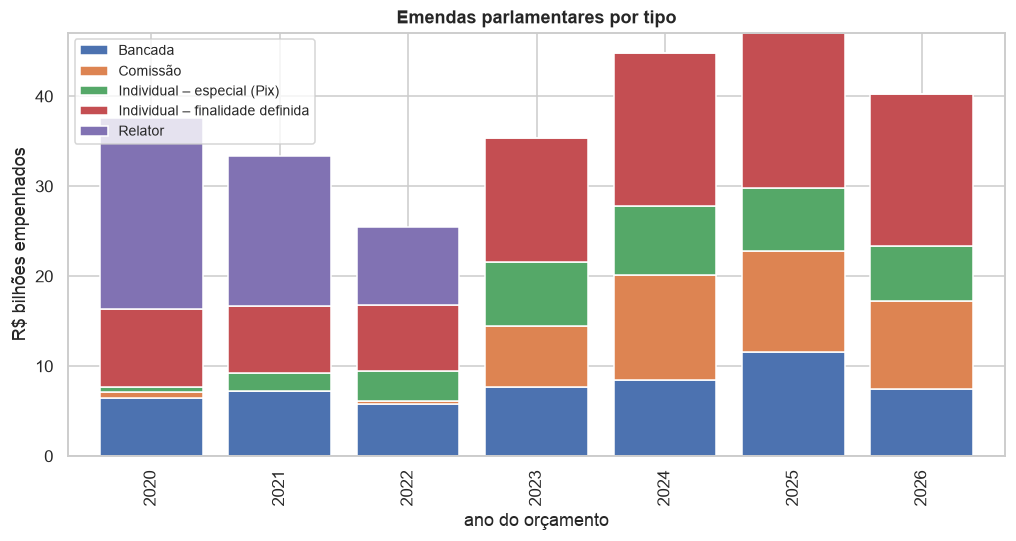

In [3]:
emp = (e.assign(tipo=e["tipo"].map(CURTO)).groupby(["ano", "tipo"])["valor_empenhado"].sum() / 1e9).unstack("tipo")
ax = emp.plot.bar(stacked=True, width=.8)
ax.set_ylabel("R$ bilhões empenhados"); ax.set_xlabel("ano do orçamento")
ax.set_title("Emendas parlamentares por tipo"); ax.legend(fontsize=9, loc="upper left"); plt.show()

**Leitura.** Depois do fim das emendas de relator (2022), o dinheiro migrou para as emendas de comissão e de bancada. As
individuais cresceram e, dentro delas, as transferências especiais ficaram com cerca de um terço.

## 2. Quando foi pago: o calendário eleitoral
Pagamentos por mês, de 2022 a 2026, somando o pagamento do próprio ano e os restos a pagar. A lei eleitoral proíbe
transferências voluntárias para estados e municípios nos três meses anteriores à eleição; as emendas individuais seguem
essa regra.

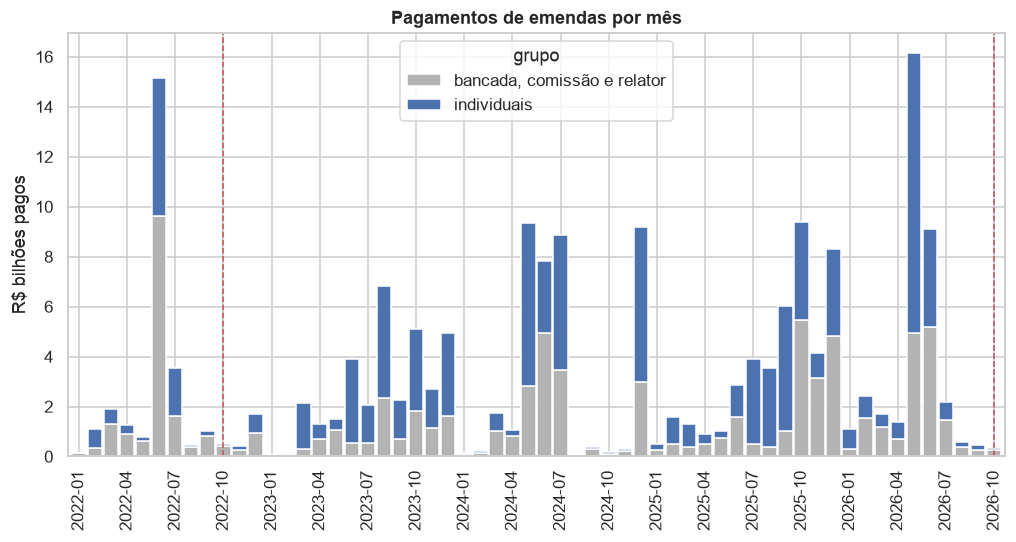

Fração do ano pago de janeiro a junho: 2022: 73%, 2023: 27%, 2024: 52%, 2025: 19%, 2026: 90% (2026 vai só até outubro)


In [4]:
p = pagos[pagos["ano_pagamento"] >= 2022].copy()
p["mes"] = pd.PeriodIndex.from_fields(year=p["ano_pagamento"], month=p["mes_pagamento"], freq="M")
p["grupo"] = np.where(p["tipo"].str.startswith("Emenda Individual"), "individuais", "bancada, comissão e relator")
m = (p.groupby(["mes", "grupo"])["valor"].sum() / 1e9).unstack("grupo").fillna(0)
m.index = m.index.astype(str)  # barras em posições 0..n-1, uma por mês
ax = m.plot.bar(stacked=True, width=.9, color=["0.7", "C0"])
ax.set_xticks(range(0, len(m), 3), m.index[::3], rotation=90)
ax.set_ylabel("R$ bilhões pagos"); ax.set_xlabel(""); ax.set_title("Pagamentos de emendas por mês")
for ano in (2022, 2026):
    ax.axvline(list(m.index).index(f"{ano}-10"), color="C3", ls="--", lw=1)  # mês da eleição
plt.show()

anos = p
antes = anos[anos["mes_pagamento"] <= 6].groupby("ano_pagamento")["valor"].sum() / anos.groupby("ano_pagamento")["valor"].sum()
print("Fração do ano pago de janeiro a junho:", ", ".join(f"{a}: {v:.0%}" for a, v in antes.items()),
      "(2026 vai só até outubro)")

**Leitura.** Em ano de eleição o pagamento se concentra antes de julho, quando começa a proibição. Isso vale para as
eleições gerais (2022, 2026) e para as municipais (2024), quando prefeitos e vereadores aliados disputam. Em 2026 o pico
foi em maio. Em 2023 e 2025 os pagamentos se espalham pelo segundo semestre.

## 3. Para onde foi
O arquivo principal de emendas não diz o município de destino da maioria das emendas individuais ("MÚLTIPLO" ou só a
UF). O arquivo de pagamentos diz o município de quem recebeu, e é ele que usamos. Uma exceção importante: nas emendas
com finalidade definida, boa parte do dinheiro passa pelo **Banco do Brasil em Brasília**, que é só o intermediário, e o
destino final se perde.

In [5]:
ind = p[p["tipo"].str.startswith("Emenda Individual") & (p["ano_pagamento"] >= 2023)].copy()
ind["destino"] = np.select(
    [ind["favorecido"].str.contains("BANCO DO BRASIL", na=False),
     ind["natureza_juridica"].str.contains("Município|Municipal", na=False),
     ind["natureza_juridica"].str.contains("Estado|Estadual", na=False),
     ind["natureza_juridica"].str.contains("Privad|Empresária|Cooperativa", na=False)],
    ["Banco do Brasil (intermediário)", "prefeitura ou fundo municipal", "estado ou fundo estadual", "entidade privada"],
    "outros")
d = (ind.groupby(["tipo", "destino"])["valor"].sum() / 1e9).unstack("tipo").fillna(0)
d.columns = [c.replace("Emenda Individual - Transferências ", "") for c in d.columns]
d["total"] = d.sum(axis=1)
d.loc["total"] = d.sum()
display(d.round(2))
print(f"Fração das emendas individuais (pagas 2023–2026) sem destino identificável: "
      f"{d.loc['Banco do Brasil (intermediário)', 'total'] / d.loc['total', 'total']:.0%}")

,Especiais,com Finalidade Definida,total
destino,,,
Banco do Brasil (intermediário),0.01,20.56,20.58
entidade privada,0.01,8.68,8.69
estado ou fundo estadual,2.08,2.53,4.61
outros,0.00,0.53,0.54
prefeitura ou fundo municipal,25.80,27.39,53.19
total,27.91,59.69,87.60


Fração das emendas individuais (pagas 2023–2026) sem destino identificável: 23%


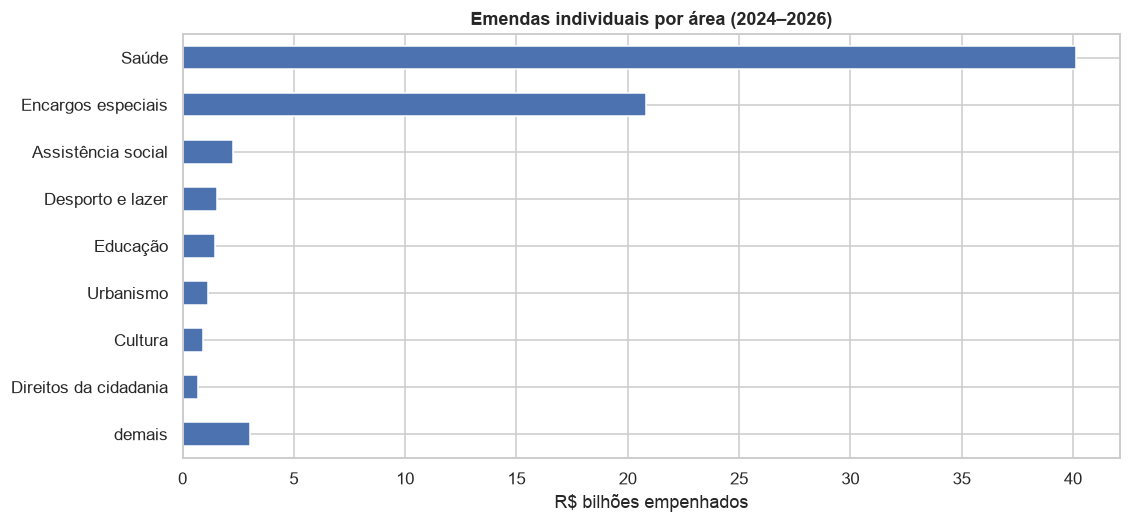

In [6]:
func = emendas[emendas["tipo"].str.startswith("Emenda Individual") & emendas["ano"].between(E.ANO_INICIO, 2026)]
f = func.groupby("funcao")["valor_empenhado"].sum().sort_values(ascending=False) / 1e9
f = pd.concat([f.head(8), pd.Series({"demais": f.iloc[8:].sum()})])
ax = f[::-1].plot.barh(color="C0")
ax.set_xlabel("R$ bilhões empenhados"); ax.set_title(f"Emendas individuais por área ({E.ANO_INICIO}–2026)"); plt.show()

**Leitura.** As transferências especiais vão quase todas para prefeituras e estados. Nas de finalidade definida, o
maior destino identificado são os fundos municipais (principalmente de saúde). O Banco do Brasil aparece como intermediário em uma fatia grande, e por isso as análises por município
subestimam o dinheiro que chega a cada lugar. Saúde concentra a maior parte do valor: a Constituição obriga que metade
das emendas individuais vá para a saúde.

## 4. Os deputados: quanto cada um destinou e com que estratégia
A partir daqui a unidade é o deputado eleito em 2022. As medidas, todas de emendas individuais dos orçamentos de
2024 a 2026 pagas até setembro de 2026 (o mês anterior à eleição):

| coluna | o que mede |
|---|---|
| `emendas_pagas` | valor pago, em R$ |
| `pct_especial` | fração paga como transferência especial ("Pix") |
| `pct_pago_2026` | fração paga no ano da eleição |
| `pct_na_base` | fração do valor com município identificado que foi para a **base eleitoral** do deputado: os municípios que, somados, deram metade dos votos dele em 2022 |
| `governismo` | fração dos votos Sim/Não na Câmara (2023–2026) que seguiram a orientação do Governo |

O orçamento de 2023 fica de fora porque as emendas dele foram apresentadas em 2022, pela legislatura anterior: só os
deputados reeleitos em 2022 as têm.

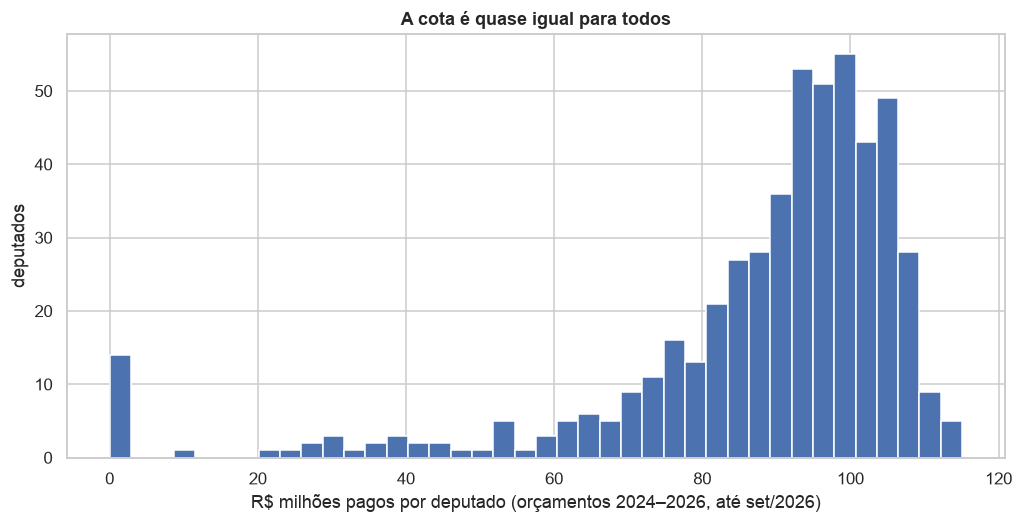

Quem teve emenda própria nos três orçamentos (464 deputados): metade recebeu entre R$ 88 e 102 milhões.
32 deputados receberam menos da metade da mediana (R$ 94 milhões). Na lista há ministros, secretários estaduais e deputados que
perderam o mandato ou morreram; nesses casos quem assumiu a cadeira apresentou as emendas:
Rejane Dias, Marcelo Lima, Milton Vieira, Luiz Marinho, Jhonatan de Jesus, Marco Bertaiolli, Enio Verri, Deltan Dallagnol, Marina Silva, Priscila Costa, Silvio Costa Filho, Alexandre Padilha, Sônia Guajajara, Paulo Teixeira, Aline Gurgel, Chiquinho Brazão, Paulo Pimenta, Washington Quaquá, Guilherme Derrite, Gerlen Diniz, Gustavo Gayer, Juscelino Filho, Abilio Brunini, Amália Barros, Paulinho Freire, Carmen Zanotto, Ricardo Silva, Alberto Mourão, Glauber Braga, Marcelo Crivella, Julio Cesar Ribeiro, Delegado Bruno Lima


In [7]:
fig, ax = plt.subplots()
ax.hist(dep["emendas_pagas"] / 1e6, bins=40, color="C0")
ax.set_xlabel("R$ milhões pagos por deputado (orçamentos 2024–2026, até set/2026)"); ax.set_ylabel("deputados")
ax.set_title("A cota é quase igual para todos"); plt.show()

poucos = dep[dep["emendas_pagas"] < dep["emendas_pagas"].median() / 2].sort_values("emendas_pagas")
inteiro = dep.loc[dep["anos_com_emendas"] == 3, "emendas_pagas"] / 1e6
print(f"Quem teve emenda própria nos três orçamentos ({len(inteiro)} deputados): metade recebeu entre "
      f"R$ {inteiro.quantile(.25):.0f} e {inteiro.quantile(.75):.0f} milhões.")
print(f"{len(poucos)} deputados receberam menos da metade da mediana (R$ {dep['emendas_pagas'].median() / 1e6:.0f} milhões). "
      "Na lista há ministros, secretários estaduais e deputados que")
print("perderam o mandato ou morreram; nesses casos quem assumiu a cadeira apresentou as emendas:")
print(", ".join(poucos["nome"]))

In [8]:
grandes = dep["sg_partido_2022"].value_counts().loc[lambda s: s >= 10].index
partidos = (dep[dep["sg_partido_2022"].isin(grandes)].groupby("sg_partido_2022")
            .agg(deputados=("nome", "size"), emendas_milhoes=("emendas_pagas", lambda s: s.median() / 1e6),
                 pct_especial=("pct_especial", "median"), pct_na_base=("pct_na_base", "median"),
                 governismo=("governismo", "median"))
            .sort_values("governismo"))
partidos

,deputados,emendas_milhoes,pct_especial,pct_na_base,governismo
sg_partido_2022,,,,,
PL,98,90.47,0.35,0.27,0.29
PSDB,13,94.44,0.33,0.38,0.76
UNIÃO,57,95.89,0.34,0.32,0.76
PP,47,97.18,0.40,0.35,0.79
REPUBLICANOS,40,90.83,0.37,0.29,0.80
MDB,41,98.68,0.42,0.36,0.81
PSD,42,98.06,0.39,0.34,0.82
PODE,14,93.62,0.38,0.27,0.85
PSOL,13,68.18,0.00,0.54,0.86


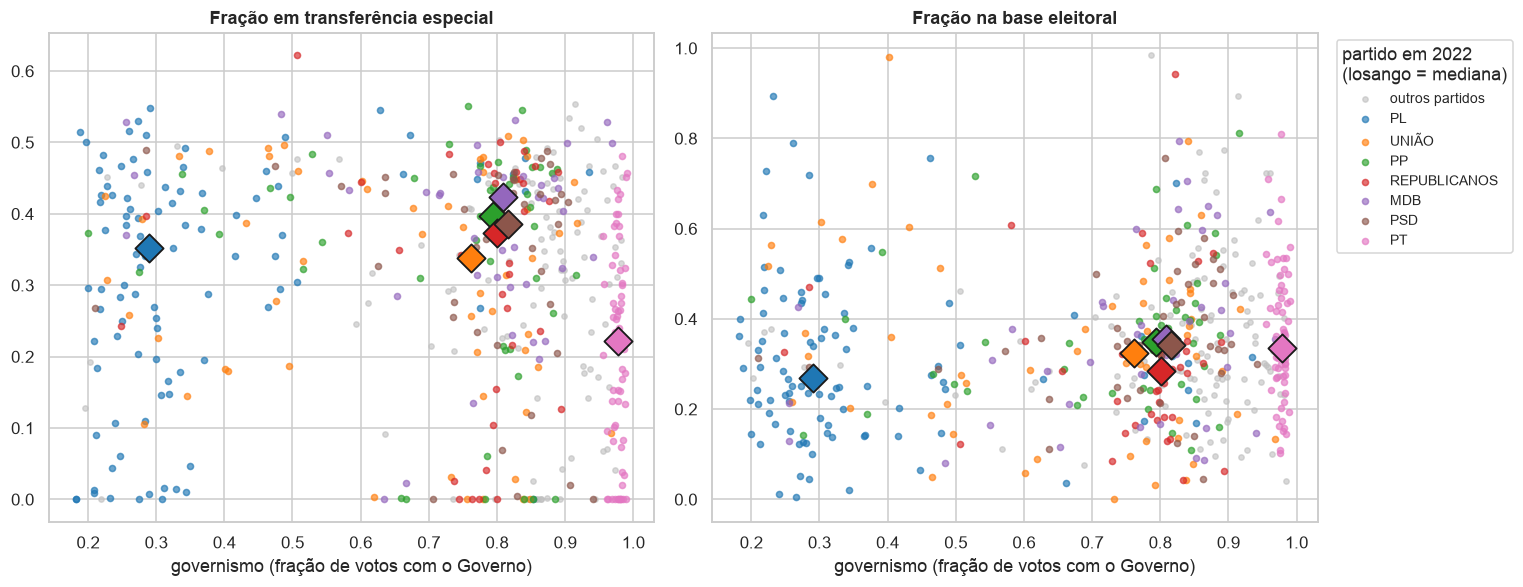

               emendas_pagas  pct_especial  pct_pago_2026  pct_na_base  \
emendas_pagas           1.00          0.34           0.14        -0.05   
pct_especial            0.34          1.00          -0.40        -0.03   
pct_pago_2026           0.14         -0.40           1.00         0.02   
pct_na_base            -0.05         -0.03           0.02         1.00   
governismo              0.18         -0.13           0.39         0.14   

               governismo  
emendas_pagas        0.18  
pct_especial        -0.13  
pct_pago_2026        0.39  
pct_na_base          0.14  
governismo           1.00  


In [9]:
CORES = dict(zip(["PL", "UNIÃO", "PP", "REPUBLICANOS", "MDB", "PSD", "PT"], sns.color_palette("tab10")))
dep["partido_grafico"] = dep["sg_partido_2022"].where(dep["sg_partido_2022"].isin(CORES), "outros")
fig, axs = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True)
for ax, col, titulo in zip(axs, ["pct_especial", "pct_na_base"], ["Fração em transferência especial", "Fração na base eleitoral"]):
    o = dep[dep["partido_grafico"] == "outros"]
    ax.scatter(o["governismo"], o[col], s=12, color="0.75", alpha=.6, label="outros partidos")
    for sg, cor in CORES.items():
        g = dep[dep["partido_grafico"] == sg]
        ax.scatter(g["governismo"], g[col], s=16, color=cor, alpha=.65, label=sg)
        # mediana do partido: marcador grande com borda preta
        ax.scatter(g["governismo"].median(), g[col].median(), s=170, color=cor, edgecolor="k", lw=1.2, marker="D", zorder=5)
    ax.set_xlabel("governismo (fração de votos com o Governo)"); ax.set_title(titulo)
axs[1].legend(title="partido em 2022\n(losango = mediana)", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()
print(dep[["emendas_pagas", "pct_especial", "pct_pago_2026", "pct_na_base", "governismo"]].corr(method="spearman").round(2))

**Leitura.** Como a cota é igual por lei, o valor pago quase não varia entre quem exerceu o mandato inteiro: o
alinhamento com o governo não muda o **quanto** um deputado consegue destinar. O que varia é a estratégia: quanto vai
como transferência especial e quanto fica concentrado na própria base. O PSOL não usa transferência especial.

## 5. Pergunta A: emendas e reeleição
Dos 513 eleitos em 2022, uma parte não disputou a Câmara em 2026 (concorreu a outro cargo ou não concorreu). A pergunta
só faz sentido para quem tentou a reeleição.

In [10]:
print(f"Eleitos em 2022: {len(dep)}")
print(f"   candidatos a deputado federal em 2026: {dep['concorreu_2026'].sum()}")
print(f"   reeleitos: {dep['reeleito'].sum()} ({dep.loc[dep['concorreu_2026'], 'reeleito'].mean():.0%} de quem tentou)")
print(f"   mudaram de partido entre 2022 e 2026 (entre quem tentou): {dep.loc[dep['concorreu_2026'], 'mudou_partido'].mean():.0%}")
r = dep[dep["concorreu_2026"]].copy()
r["reeleito"] = r["reeleito"].astype(int)

Eleitos em 2022: 513
   candidatos a deputado federal em 2026: 415
   reeleitos: 297 (72% de quem tentou)
   mudaram de partido entre 2022 e 2026 (entre quem tentou): 33%


In [11]:
def taxa_por_faixa(col, rotulos=("baixa", "média", "alta")):
    faixa = pd.qcut(r[col].rank(method="first"), 3, labels=rotulos)
    return r.groupby(faixa, observed=True).agg(
        deputados=("reeleito", "size"), valor_mediano=(col, "median"),
        taxa_reeleicao=("reeleito", "mean"), crescimento_mediano_votos=("crescimento_votos", "median"))

for col in ("emendas_pagas", "pct_na_base", "pct_especial", "pct_pago_2026"):
    print(f"\n{col} (terços)")
    display(taxa_por_faixa(col))

print("\ngovernismo (faixas fixas: a oposição fica quase toda abaixo de 0,4)")
display(r.groupby(pd.cut(r["governismo"], [0, .4, .6, .8, .9, 1]), observed=True)
         .agg(deputados=("reeleito", "size"), taxa_reeleicao=("reeleito", "mean"), mudou_partido=("mudou_partido", "mean")))


emendas_pagas (terços)


,deputados,valor_mediano,taxa_reeleicao,crescimento_mediano_votos
emendas_pagas,,,,
baixa,139,"82,220,732.93",0.68,0.01
média,138,"95,006,477.19",0.69,0.02
alta,138,"104,135,609.82",0.78,0.02



pct_na_base (terços)


,deputados,valor_mediano,taxa_reeleicao,crescimento_mediano_votos
pct_na_base,,,,
baixa,137,0.18,0.62,-0.08
média,136,0.32,0.74,0.02
alta,137,0.50,0.80,0.05



pct_especial (terços)


,deputados,valor_mediano,taxa_reeleicao,crescimento_mediano_votos
pct_especial,,,,
baixa,137,0.12,0.71,-0.02
média,136,0.34,0.71,-0.01
alta,137,0.46,0.74,0.08



pct_pago_2026 (terços)


,deputados,valor_mediano,taxa_reeleicao,crescimento_mediano_votos
pct_pago_2026,,,,
baixa,137,0.24,0.75,0.05
média,136,0.30,0.71,-0.03
alta,137,0.36,0.69,0.05



governismo (faixas fixas: a oposição fica quase toda abaixo de 0,4)


,deputados,taxa_reeleicao,mudou_partido
governismo,,,
"(0.0, 0.4]",77,0.86,0.22
"(0.4, 0.6]",30,0.67,0.37
"(0.6, 0.8]",80,0.57,0.44
"(0.8, 0.9]",130,0.73,0.42
"(0.9, 1.0]",98,0.71,0.21


### Dinheiro de campanha
Receitas declaradas ao TSE pela candidatura de 2026 (`uv run coletar-legislativo --etapas contas`). A maior parte vem do
Fundo Especial de Financiamento de Campanha (FEFC), que o partido distribui como quiser. O teto de gastos para deputado
federal limita o valor. Cada candidato aparece com a última prestação entregue; quem ainda não entregou a final pode ter
receitas faltando.

In [12]:
print("Última prestação entregue, por resultado:")
display(pd.crosstab(r["tipo_prestacao_2026"].fillna("nenhuma"), r["reeleito"].map({1: "reeleito", 0: "não reeleito"}),
                    normalize="columns").round(2))
display(taxa_por_faixa("receitas_2026"))
print(f"Mediana das receitas: R$ {r['receitas_2026'].median() / 1e6:.2f} milhões, "
      f"{r['pct_fefc_2026'].median():.0%} delas do FEFC.")
print("Correlação de Spearman das receitas com a concentração na base:",
      f"{r[['receitas_2026', 'pct_na_base']].corr('spearman').iloc[0, 1]:+.2f}")

Última prestação entregue, por resultado:


reeleito,não reeleito,reeleito
tipo_prestacao_2026,,
FINAL,0.03,0.07
PARCIAL,0.25,0.25
RELATÓRIO FINANCEIRO,0.71,0.68
nenhuma,0.01,0.00


,deputados,valor_mediano,taxa_reeleicao,crescimento_mediano_votos
receitas_2026,,,,
baixa,138,"1,939,011.68",0.62,-0.01
média,138,"2,710,724.83",0.74,0.01
alta,138,"3,100,000.00",0.80,0.05


Mediana das receitas: R$ 2.71 milhões, 92% delas do FEFC.
Correlação de Spearman das receitas com a concentração na base: -0.08


**Regressões.** Duas medidas de resultado, para quem disputou em 2026:
- `reeleito` (0 ou 1), em modelo de probabilidade linear: o coeficiente é a mudança na chance de reeleição;
- `crescimento_votos`: log dos votos em 2026 sobre os de 2022 (0,10 ≈ 10% mais votos).

Controles: força eleitoral em 2022 (log da fatia dos votos da UF), se é veterano (já era deputado antes de 2023), se
mudou de partido, número de municípios na base (deputados de base concentrada têm menos municípios onde a emenda "conta")
e efeitos fixos de UF. Erros-padrão robustos (HC1). `emendas_pagas` entra em R$ 10 milhões.

Cada relação é estimada em quatro modelos: só esses controles (`UF`), mais efeito fixo de partido (`UF + partido`), mais
as receitas de campanha de 2026 em R$ milhões (`UF + receitas`) e com os dois (`UF + partido + receitas`). As receitas
podem ser em parte consequência da força do deputado (o partido manda mais dinheiro para quem tem mais chance), então o
modelo com elas é um teste de robustez, não a estimativa principal.

In [13]:
r["emendas_10mi"] = r["emendas_pagas"] / 1e7
r["log_fatia_2022"] = np.log(r["fatia_uf_2022"])
r["log_mun_base"] = np.log(r["n_municipios_base"])
r["receitas_mi"] = r["receitas_2026"] / 1e6
CONTROLES = "log_fatia_2022 + veterano + mudou_partido + log_mun_base + C(uf)"
MODELOS = {"UF": "", "UF + partido": " + C(sg_partido_2022)", "UF + receitas": " + receitas_mi",
           "UF + partido + receitas": " + C(sg_partido_2022) + receitas_mi"}
amostra = r[r["receitas_mi"].notna()]  # a mesma amostra em todos os modelos: quem tem receitas declaradas

linhas = []
for y in ("reeleito", "crescimento_votos"):
    for x in ("emendas_10mi", "pct_na_base", "pct_especial", "pct_pago_2026", "governismo", "receitas_mi"):
        for nome, extra in MODELOS.items():
            if x == "receitas_mi" and "receitas" not in nome:
                continue
            mod = smf.ols(f"{y} ~ {x} + {CONTROLES}{extra}", data=amostra).fit(cov_type="HC1")  # patsy ignora termo repetido
            ic = mod.conf_int().loc[x]
            linhas.append({"resultado": y, "variável": x, "modelo": nome, "coef": mod.params[x],
                           "IC 95% inf": ic[0], "IC 95% sup": ic[1], "p": mod.pvalues[x], "n": int(mod.nobs)})
R = pd.DataFrame(linhas).set_index(["resultado", "variável", "modelo"])
R.style.format({"coef": "{:.3f}", "IC 95% inf": "{:.3f}", "IC 95% sup": "{:.3f}", "p": "{:.3f}", "n": "{:d}"}) \
    .map(lambda v: "font-weight: bold" if v < .05 else "", subset=["p"])

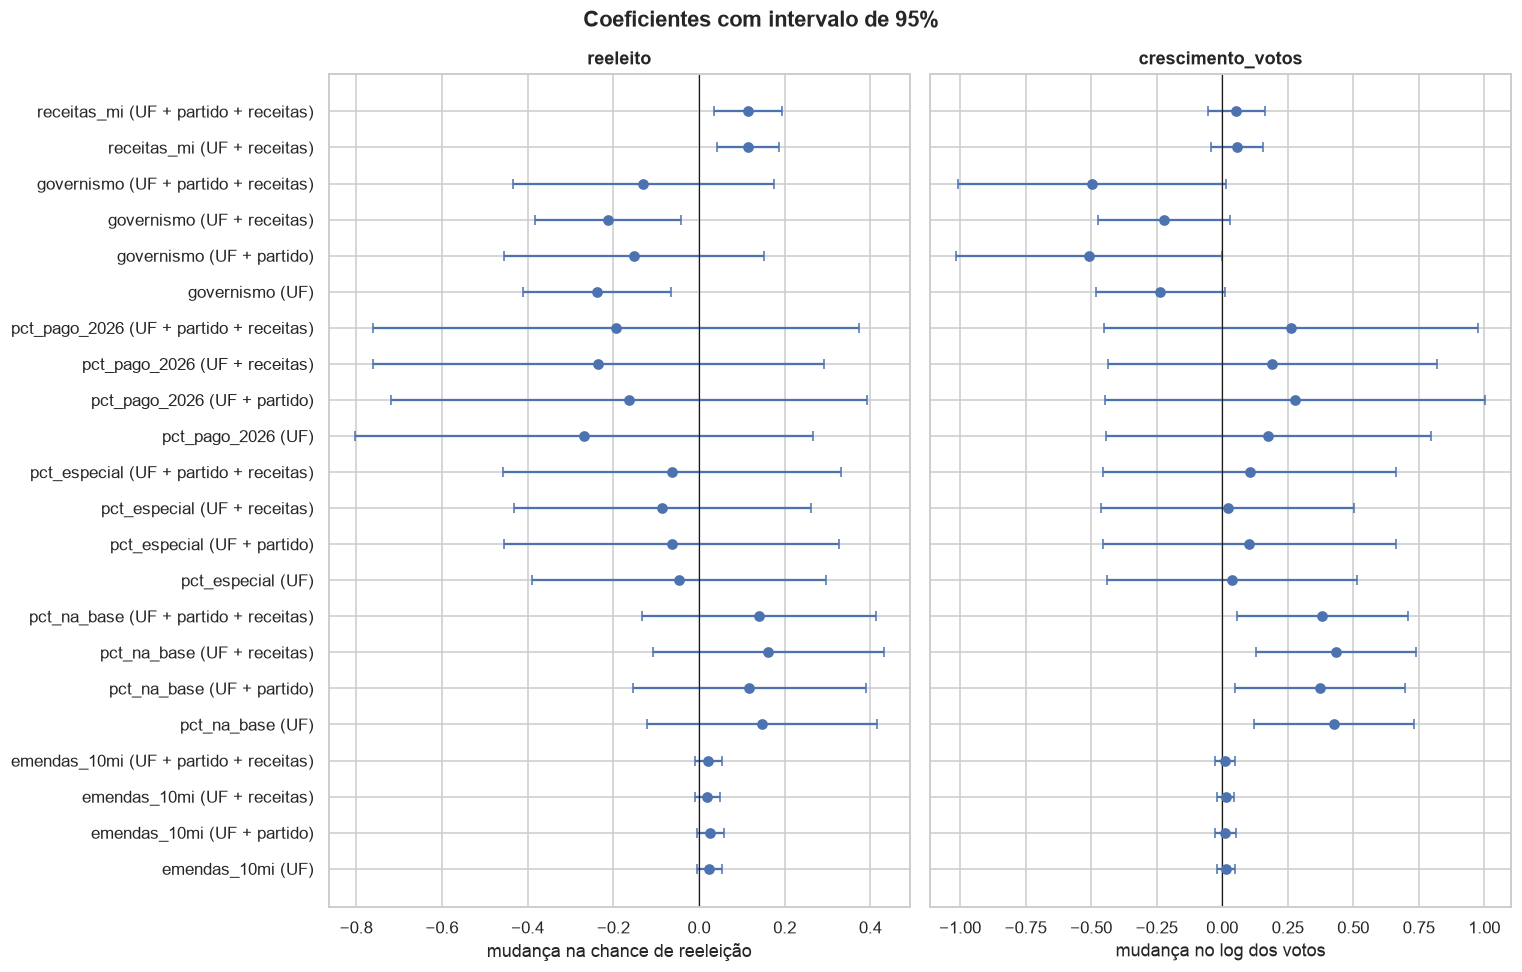

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(14, 9), sharey=True)
for ax, y in zip(axs, ("reeleito", "crescimento_votos")):
    s = R.xs(y).reset_index()
    s["rótulo"] = s["variável"] + " (" + s["modelo"] + ")"
    ax.errorbar(s["coef"], range(len(s)), xerr=[s["coef"] - s["IC 95% inf"], s["IC 95% sup"] - s["coef"]], fmt="o", capsize=3)
    ax.axvline(0, color="k", lw=.8); ax.set_title(y)
    ax.set_yticks(range(len(s)), s["rótulo"]); ax.invert_yaxis()
axs[0].set_xlabel("mudança na chance de reeleição"); axs[1].set_xlabel("mudança no log dos votos")
fig.suptitle("Coeficientes com intervalo de 95%", weight="bold"); plt.tight_layout(); plt.show()

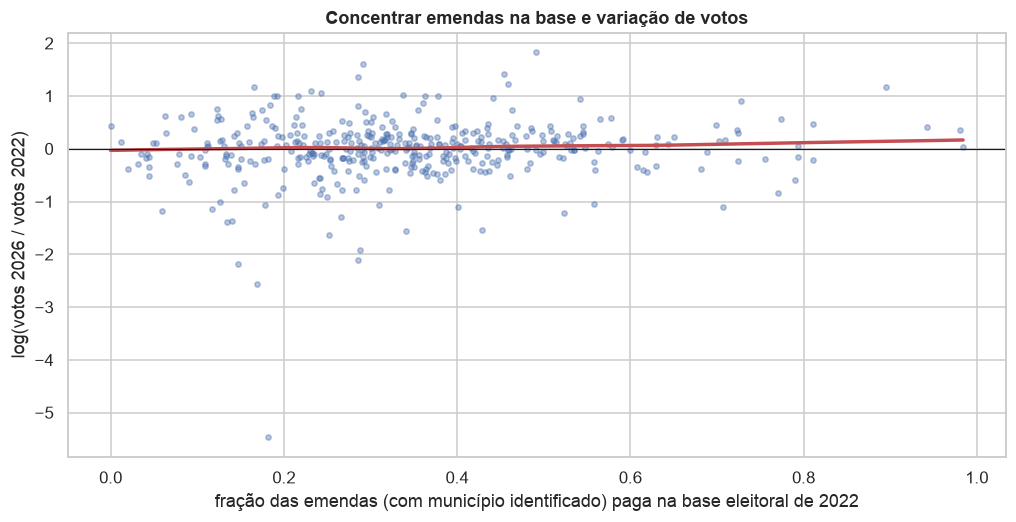

In [15]:
fig, ax = plt.subplots()
sns.regplot(data=r, x="pct_na_base", y="crescimento_votos", lowess=True, scatter_kws={"s": 12, "alpha": .4}, line_kws={"color": "C3"}, ax=ax)
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("fração das emendas (com município identificado) paga na base eleitoral de 2022")
ax.set_ylabel("log(votos 2026 / votos 2022)"); ax.set_title("Concentrar emendas na base e variação de votos")
plt.show()

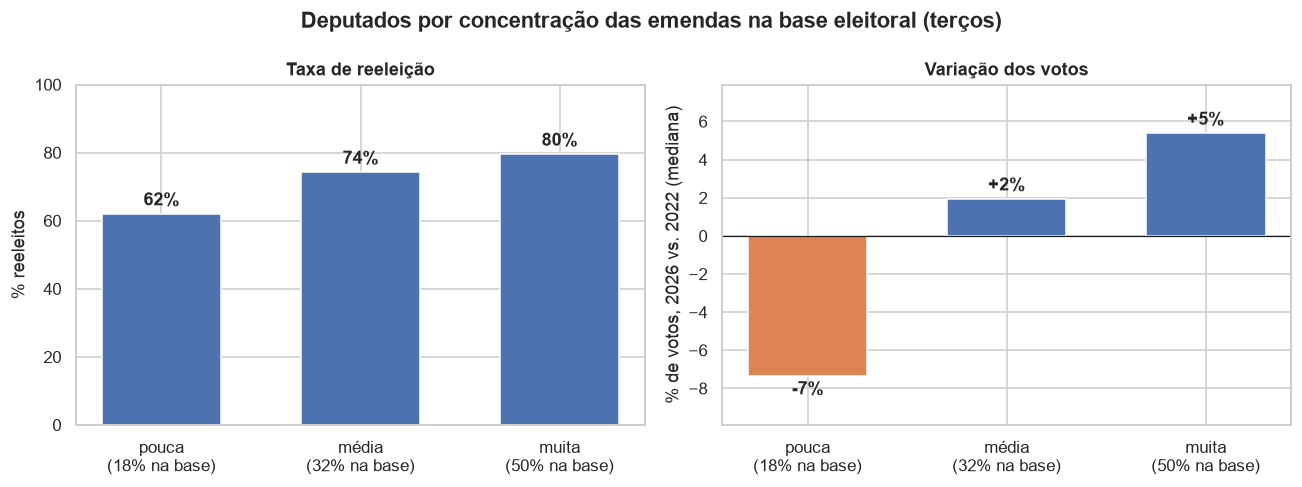

In [16]:
t = taxa_por_faixa("pct_na_base", ("pouca", "média", "muita"))
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
rot = [f"{f}\n({v:.0%} na base)" for f, v in zip(t.index, t["valor_mediano"])]
axs[0].bar(rot, t["taxa_reeleicao"] * 100, color="C0", width=.6)
axs[0].set_ylim(0, 100); axs[0].set_ylabel("% reeleitos"); axs[0].set_title("Taxa de reeleição")
crescimento = (np.exp(t["crescimento_mediano_votos"]) - 1) * 100
axs[1].bar(rot, crescimento, color=np.where(crescimento >= 0, "C0", "C1"), width=.6)
axs[1].axhline(0, color="k", lw=.8); axs[1].set_ylabel("% de votos, 2026 vs. 2022 (mediana)")
axs[1].margins(y=.2)  # espaço para os rótulos acima e abaixo das barras
axs[1].set_title("Variação dos votos")
for ax, vals, fmt in ((axs[0], t["taxa_reeleicao"] * 100, "{:.0f}%"), (axs[1], crescimento, "{:+.0f}%")):
    for x, v in enumerate(vals):
        ax.annotate(fmt.format(v), (x, v), ha="center", va="bottom" if v >= 0 else "top", xytext=(0, 3 if v >= 0 else -3),
                    textcoords="offset points", weight="bold")
fig.suptitle("Deputados por concentração das emendas na base eleitoral (terços)", weight="bold")
plt.tight_layout(); plt.show()

**Leitura.**
- **Valor pago:** a associação com reeleição é pequena e não significativa a 5%. Era o esperado: com cota igual, quase não
  há variação para medir, e a que existe vem de licenças.
- **Concentração na base:** quem mandou uma fração maior das emendas para os municípios que o elegeram em 2022 teve mais
  votos em 2026, inclusive comparando deputados do mesmo partido e da mesma UF. Na chance de reeleição o sinal é o mesmo,
  mas o intervalo inclui zero.
- **Transferência especial e pagamento no ano da eleição:** nenhuma associação.
- **Governismo:** a oposição (quase toda do PL) se reelegeu mais que o centro. Com efeito fixo de partido a diferença na
  reeleição some, ou seja, é efeito do partido, não das emendas.
- **Receitas de campanha:** é a variável mais associada à reeleição (cada R$ 1 milhão a mais, cerca de 11 pontos de
  chance), mas não ao crescimento dos votos. Incluí-la quase não muda os outros coeficientes: o dinheiro de campanha não
  anda junto com a concentração das emendas na base (correlação perto de zero), então não explica essa relação.

## 6. Resumo automático

In [17]:
def frase(y, x, fe="UF"):
    l = R.loc[(y, x, fe)]
    return f"coef {l['coef']:+.3f} (IC 95% {l['IC 95% inf']:+.3f} a {l['IC 95% sup']:+.3f}, p = {l['p']:.3f})"

print(f"• {dep['concorreu_2026'].sum()} dos 513 eleitos em 2022 disputaram a Câmara em 2026; "
      f"{r['reeleito'].mean():.0%} deles se reelegeram.")
print(f"• Valor pago: mediana de R$ {dep['emendas_pagas'].median() / 1e6:.0f} milhões por deputado; "
      f"a variação vem quase toda de licença ou perda de mandato, não de escolha.")
print(f"• Mais R$ 10 milhões em emendas pagas → chance de reeleição: {frase('reeleito', 'emendas_10mi')}")
print(f"• Concentração na base (de 0 a 100%) → chance de reeleição: {frase('reeleito', 'pct_na_base')}")
print(f"                                     → crescimento dos votos: {frase('crescimento_votos', 'pct_na_base')}")
print(f"  (com efeito fixo de partido: {frase('crescimento_votos', 'pct_na_base', 'UF + partido')})")
print(f"• Fração em transferência especial → crescimento dos votos: {frase('crescimento_votos', 'pct_especial')}")
print(f"• Governismo → chance de reeleição: {frase('reeleito', 'governismo')}")
print(f"• Mais R$ 1 milhão de receitas de campanha → chance de reeleição: {frase('reeleito', 'receitas_mi', 'UF + receitas')}")
print(f"  Concentração na base → crescimento dos votos, controlando partido e receitas: "
      f"{frase('crescimento_votos', 'pct_na_base', 'UF + partido + receitas')}")
print("\nLembretes: associação, não causa. Deputados com base sólida podem tanto mandar mais emendas para ela quanto crescer")
print("nos votos por outros motivos. As receitas de campanha ainda não são as da prestação final. A pergunta B (emendas ×")
print("votos por município, com efeitos fixos de deputado e município) controla melhor esses fatores e é o próximo passo.")

• 415 dos 513 eleitos em 2022 disputaram a Câmara em 2026; 72% deles se reelegeram.
• Valor pago: mediana de R$ 94 milhões por deputado; a variação vem quase toda de licença ou perda de mandato, não de escolha.
• Mais R$ 10 milhões em emendas pagas → chance de reeleição: coef +0.024 (IC 95% -0.004 a +0.053, p = 0.092)
• Concentração na base (de 0 a 100%) → chance de reeleição: coef +0.147 (IC 95% -0.122 a +0.417, p = 0.285)
                                     → crescimento dos votos: coef +0.428 (IC 95% +0.122 a +0.733, p = 0.006)
  (com efeito fixo de partido: coef +0.373 (IC 95% +0.049 a +0.697, p = 0.024))
• Fração em transferência especial → crescimento dos votos: coef +0.038 (IC 95% -0.440 a +0.515, p = 0.877)
• Governismo → chance de reeleição: coef -0.238 (IC 95% -0.410 a -0.066, p = 0.007)
• Mais R$ 1 milhão de receitas de campanha → chance de reeleição: coef +0.114 (IC 95% +0.042 a +0.187, p = 0.002)
  Concentração na base → crescimento dos votos, controlando partido e receit